<a href="https://colab.research.google.com/github/sebasarellano/Aprendizaje_Automatico/blob/main/03_1_Procesado_Datos_Arellano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Notebooks/03-1-Procesado-Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
  <tr>
    <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
      <img src="https://i.imgur.com/nt7hloA.png" width="100">
    </td>
    <td style="width: 2px; text-align: center;">
      <font color="#0030A1" size="7">|</font><br>
      <font color="#0030A1" size="7">|</font>
    </td>
    <td>
      <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
        <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
      </font></p>
      <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
        Aprendizaje Automático Inicial &bull; Preprocesado de Datos
      </font></p>
      <p style="font-style: oblique;"><font color="#0030A1" size="3">
        Andrés Merino &bull; Periodo 2026-2
      </font></p>
    </td>
  </tr>
</table>

**Estudiante:** Sebastián Arellano

---
## <font color='264CC7'> Introducción </font>

En este notebook se presentarán las técnicas de preprocesado más utilizadas en aprendizaje automático:

- Normalización y estandarización de datos.
- Discretización de variables continuas.
- One-Hot Encoding de variables categóricas.
- Reducción de dimensionalidad mediante Análisis de Componentes Principales (PCA).

Los paquetes necesarios son:

**Alcance:** las transformaciones sobre Iris completo son demostraciones exploratorias, sin evaluar capacidad predictiva. Para un modelo supervisado, separar primero entrenamiento, validación y prueba; aprender escalas, categorías, intervalos y PCA solo de entrenamiento. Estandarizar no vuelve normales los datos ni impone un rango. Min-Max puede producir valores fuera de [0,1] al transformar datos nuevos. Las fórmulas manuales requieren revisar denominadores nulos.


In [ ]:
import pandas as pd
from sklearn import datasets
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer, OneHotEncoder
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

---
## <font color='264CC7'> Cargar el conjunto de datos Iris </font>


In [ ]:
iris = datasets.load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="species")
df = pd.concat([X, y], axis=1)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


---
## <font color='264CC7'> Normalización (escalado) </font>

Tenemos varias técnicas de normalización, las más comunes son:
- Normalización por el máximo:
  $$ x_i' = \frac{x_i}{x_{\max}} $$
- Normalización por la diferencia (min-max):
  $$ x_i' = \frac{x_i - x_{\min}}{x_{\max} - x_{\min}} $$
- Normalización basada en la media y desviación estándar (Estandarización):
  $$ x_i' = \frac{x_i - \mu}{\sigma} $$
  donde $\mu$ es la media y $\sigma$ la desviación estándar de la variable.


In [ ]:
# Normalización por el máximo
x_max = X.max()
X_max_normalized = X / x_max
print("Normalización por el máximo:\n")
display(X_max_normalized.head())

# Normalización Min-Max
min_max_scaler = MinMaxScaler()
X_min_max_normalized = pd.DataFrame(min_max_scaler.fit_transform(X), columns=X.columns)
print("Normalización Min-Max:\n")
display(X_min_max_normalized.head())

# Estandarización
standard_scaler = StandardScaler()
X_standardized = pd.DataFrame(standard_scaler.fit_transform(X), columns=X.columns)
print("Estandarización:\n")
display(X_standardized.head())

Normalización por el máximo:



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,0.645570,0.795455,0.202899,0.08
1,0.620253,0.681818,0.202899,0.08
2,0.594937,0.727273,0.188406,0.08
3,0.582278,0.704545,0.217391,0.08
4,0.632911,0.818182,0.202899,0.08


Normalización Min-Max:



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


Estandarización:



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


---
## <font color='264CC7'> Discretización (Binning) </font>

Se tienen dos métodos principales para discretizar variables continuas:
- Igual amplitud: Divide el rango de la variable en intervalos de igual tamaño.
- Igual frecuencia: Divide los datos en intervalos que contienen aproximadamente el mismo número de muestras.


In [ ]:
# Igual amplitud
kbins_amplitude = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='uniform')
X_binned_amplitude = pd.DataFrame(kbins_amplitude.fit_transform(X[['sepal length (cm)']]), columns=['sepal length (cm) binned'])
print("Los rangos de los bins (igual amplitud):", kbins_amplitude.bin_edges_[0])
print("Cantidad de muestras por bin (igual amplitud):", pd.Series(X_binned_amplitude['sepal length (cm) binned']).value_counts().sort_index().values, "\n")

# Igual frecuencia
kbins_frequency = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='quantile')
X_binned_frequency = pd.DataFrame(kbins_frequency.fit_transform(X[['sepal length (cm)']]), columns=['sepal length (cm) binned'])
print("Los rangos de los bins (igual frecuencia):", kbins_frequency.bin_edges_[0])
print("Cantidad de muestras por bin (igual frecuencia):", pd.Series(X_binned_frequency['sepal length (cm) binned']).value_counts().sort_index().values)

Los rangos de los bins (igual amplitud): [4.3 5.5 6.7 7.9]
Cantidad de muestras por bin (igual amplitud): [52 70 28] 

Los rangos de los bins (igual frecuencia): [4.3 5.4 6.3 7.9]
Cantidad de muestras por bin (igual frecuencia): [46 53 51]


---
## <font color='264CC7'> One-Hot Encoding </font>

Se basa en convertir cada categoría de una variable categórica en una nueva columna binaria (0 o 1), donde 1 indica la presencia de esa categoría.

<img src="https://substackcdn.com/image/fetch/$s_!6PUN!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fa8274ebc-146a-40b6-aaed-733b93943788_1871x816.png" alt="Imagen One-hot encoding" style="max-width:500px; height:auto;">

In [ ]:
# Característica nominal de ejemplo, independiente de la variable objetivo.
colores = pd.DataFrame({"color": ["rojo", "verde", "azul", "verde", "rojo"]})
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop=None)
colores_codificados = pd.DataFrame(
    onehot_encoder.fit_transform(colores),
    columns=onehot_encoder.get_feature_names_out(["color"])
)
display(colores_codificados)


,color_azul,color_rojo,color_verde
0,0.0,1.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,0.0,0.0,1.0
4,0.0,1.0,0.0


---
## <font color='264CC7'> Reducción de dimensionalidad </font>

Todo problema tiene dos dimensiones importantes: la cantidad de datos (número de muestras) y la cantidad de características (dimensionalidad).

Reducir dimensionalidad significa reducir el número de características. Reducir el número de muestras es una operación distinta; aquí recuperamos PCA como proyección a menos componentes.

Podemos aplicar Análisis de Componentes Principales (PCA) para reducir la dimensionalidad del conjunto de datos mientras se conserva la mayor cantidad de varianza posible. Primero debemos revisar la varianza explicada por cada componente principal para decidir cuántos componentes conservar.

Varianza explicada por cada componente principal:
 [0.72962445 0.22850762 0.03668922 0.00517871]


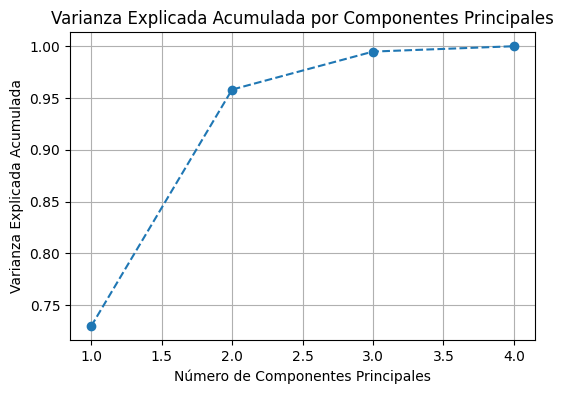

In [ ]:
# Varianza explicada por cada componente principal
pca = PCA()
pca.fit(X_standardized)
explained_variance = pca.explained_variance_ratio_
print("Varianza explicada por cada componente principal:\n", explained_variance)

# Grafico de la varianza explicada acumulada
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(explained_variance) + 1), explained_variance.cumsum(), marker='o', linestyle='--')
plt.title('Varianza Explicada Acumulada por Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid()
plt.show()

Con esto, generamos las dos primeras componentes principales y las visualizamos.

In [ ]:
# Usar las features escaladas por StandardScaler para PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)
X_pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
print("Componentes principales (PCA):\n")
display(X_pca_df.head())

Componentes principales (PCA):



,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


---

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Tomar únicamente la mitad de los datos del conjunto original y repetir la normalización y discretización. Comparar los resultados con los obtenidos con el conjunto completo.
</div>

---

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Realizar la discretización utilizando otro número de bins y comparar los resultados.
</div>

---

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;" >
<strong>Ejercicio:</strong><br>
Realizar un gráfico de dispersión (scatter plot) de las dos primeras componentes principales, coloreando los puntos según la variable objetivo `species`.
</div>

---


##Ejercicio 1

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer

# 1. Tomar únicamente la mitad de los datos (50%) de forma aleatoria
X_half = X.sample(frac=0.5, random_state=42)

# 2. Estandarizar la mitad de los datos
scaler_half = StandardScaler()
X_half_scaled = pd.DataFrame(scaler_half.fit_transform(X_half), columns=X.columns)

# 3. Discretizar la variable 'sepal length (cm)' con la mitad de los datos
kbins_half = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='uniform')
X_half_binned = pd.DataFrame(
    kbins_half.fit_transform(X_half[['sepal length (cm)']]),
    columns=['sepal length (cm) binned']
)

# 4. Comparar resultados directamente con los objetos globales existentes
print("--- Comparación de Medias (Sepal Length) ---")
print("Media (Dataset Completo):", standard_scaler.mean_[0])
print("Media (Mitad de Datos):  ", scaler_half.mean_[0])

print("\n--- Comparación de Bordes de Bins ---")
print("Bordes (Dataset Completo):", kbins_amplitude.bin_edges_[0])
print("Bordes (Mitad de Datos):  ", kbins_half.bin_edges_[0])

--- Comparación de Medias (Sepal Length) ---
Media (Dataset Completo): 5.843333333333335
Media (Mitad de Datos):   5.838666666666668

--- Comparación de Bordes de Bins ---
Bordes (Dataset Completo): [4.3 5.5 6.7 7.9]
Bordes (Mitad de Datos):   [4.4        5.56666667 6.73333333 7.9       ]


##Ejercicio 2

In [ ]:
import pandas as pd
from sklearn.preprocessing import KBinsDiscretizer

# Definir un número diferente de bins (por ejemplo, 5 bins en vez de 3)
kbins_5 = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform')

# Aplicar la transformación a la característica 'sepal length (cm)'
X_binned_5 = pd.DataFrame(
    kbins_5.fit_transform(X[['sepal length (cm)']]),
    columns=['sepal length (cm) binned']
)

# Mostrar los nuevos límites y la cantidad de elementos por bin
print("Nuevos rangos de los bins (n_bins = 5):")
print(kbins_5.bin_edges_[0])

print("\nCantidad de muestras por cada bin:")
print(X_binned_5['sepal length (cm) binned'].value_counts().sort_index())

Nuevos rangos de los bins (n_bins = 5):
[4.3  5.02 5.74 6.46 7.18 7.9 ]

Cantidad de muestras por cada bin:
sepal length (cm) binned
0.0    32
1.0    41
2.0    42
3.0    24
4.0    11
Name: count, dtype: int64


##Ejercicio 3

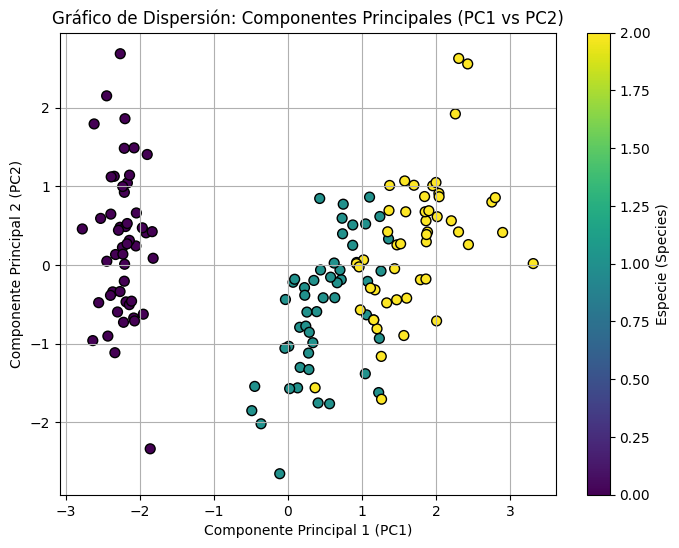

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Crear el gráfico de dispersión usando las componentes PC1 y PC2 directamente
scatter = plt.scatter(
    X_pca_df['PC1'],
    X_pca_df['PC2'],
    c=y,
    cmap='viridis',
    edgecolor='k',
    s=50
)

# Añadir títulos, etiquetas y barra de colores
plt.title('Gráfico de Dispersión: Componentes Principales (PC1 vs PC2)')
plt.xlabel('Componente Principal 1 (PC1)')
plt.ylabel('Componente Principal 2 (PC2)')
plt.colorbar(scatter, label='Especie (Species)')
plt.grid(True)

plt.show()

## De la demostración al flujo supervisado
Este ejemplo solo prepara características; no entrena ni evalúa un predictor. Compara `fit_transform` sobre entrenamiento con `transform` sobre prueba.


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler_train = StandardScaler()
X_train_scaled = scaler_train.fit_transform(X_train)
X_test_scaled = scaler_train.transform(X_test)
print("Media aprendida de entrenamiento:", scaler_train.mean_)
print("Dimensiones:", X_train_scaled.shape, X_test_scaled.shape)


**Cierre:** explica por qué no se hace `fit_transform(X_test)`. El ejemplo nominal de colores es independiente de Iris; no debe concatenarse con sus filas. En un flujo con categorías, aprender el codificador de las características de entrenamiento y decidir cómo tratar categorías nuevas.
